# Week 4 — Customer Segmentation using K-Means Clustering

**Dataset:** [Mall Customers Dataset (`vjchoudhary7/customer-segmentation-tutorial-in-python`)](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)

This notebook implements **Option 3: Customer Segmentation using Clustering**:
1. Load & inspect the Mall Customers dataset.
2. Scan Elbow & Silhouette scores (`k = 2..10`) and fit `KMeans(n_clusters=5)`.
3. Label customer groups into **`Low Spenders`**, **`Medium Spenders`**, and **`High Spenders`** with business personas.
4. Visualize segments across **Age**, **Annual Income**, and **Spending Score** and export `outputs/mall_customers_segmented.csv`.

In [1]:
import pandas as pd
from IPython.display import Image, display

from customer_segmentation import (
    CLUSTER_FEATURES_2D,
    SEGMENTED_CSV_PATH,
    load_mall_customers,
    plot_customer_segments,
    plot_segmentation_diagnostics,
    segment_customers,
)

In [2]:
df_raw = load_mall_customers()
print(f"Dataset Shape: {df_raw.shape}")
display(df_raw.head())
display(df_raw.describe().round(2))

Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [3]:
res = segment_customers(df_raw, n_clusters=5, feature_cols=CLUSTER_FEATURES_2D)
print(f"Optimal k        : {res['n_clusters']}")
print(f"Silhouette Score : {res['silhouette_score']:.4f}")

SEGMENTED_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
res["df_segmented"].to_csv(SEGMENTED_CSV_PATH, index=False)

print("\nSpender Group Summary:")
display(res["tier_summary"])

print("\nDetailed Cluster Personas:")
display(res["cluster_summary"])
display(res["df_segmented"].head(10))

Optimal k        : 5
Silhouette Score : 0.5547

Spender Group Summary:


,Spender_Group,Customers,Avg_Age,Avg_Income_k,Avg_Spending_Score,Share_Pct
0,Low Spenders,58,42.74,63.66,18.62,29.0
1,Medium Spenders,81,42.72,55.30,49.52,40.5
2,High Spenders,61,30.02,64.61,81.13,30.5



Detailed Cluster Personas:


,Cluster,Spender_Group,Customer_Persona,Customers,Avg_Age,Avg_Income_k,Avg_Spending_Score
0,1,High Spenders,Affluent VIPs (High Spenders),39,32.69,86.54,82.13
1,2,High Spenders,Young Trendsetters (High Spenders),22,25.27,25.73,79.36
2,0,Medium Spenders,Core Steady Shoppers (Medium Spenders),81,42.72,55.30,49.52
3,4,Low Spenders,Budget-Conscious Shoppers (Low Spenders),23,45.22,26.30,20.91
4,3,Low Spenders,Careful High-Earners (Low Spenders),35,41.11,88.20,17.11


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Spender_Group,Customer_Persona
0,1,Male,19,15,39,4,Low Spenders,Budget-Conscious Shoppers (Low Spenders)
1,2,Male,21,15,81,2,High Spenders,Young Trendsetters (High Spenders)
2,3,Female,20,16,6,4,Low Spenders,Budget-Conscious Shoppers (Low Spenders)
3,4,Female,23,16,77,2,High Spenders,Young Trendsetters (High Spenders)
4,5,Female,31,17,40,4,Low Spenders,Budget-Conscious Shoppers (Low Spenders)
5,6,Female,22,17,76,2,High Spenders,Young Trendsetters (High Spenders)
6,7,Female,35,18,6,4,Low Spenders,Budget-Conscious Shoppers (Low Spenders)
7,8,Female,23,18,94,2,High Spenders,Young Trendsetters (High Spenders)
8,9,Male,64,19,3,4,Low Spenders,Budget-Conscious Shoppers (Low Spenders)
9,10,Female,30,19,72,2,High Spenders,Young Trendsetters (High Spenders)


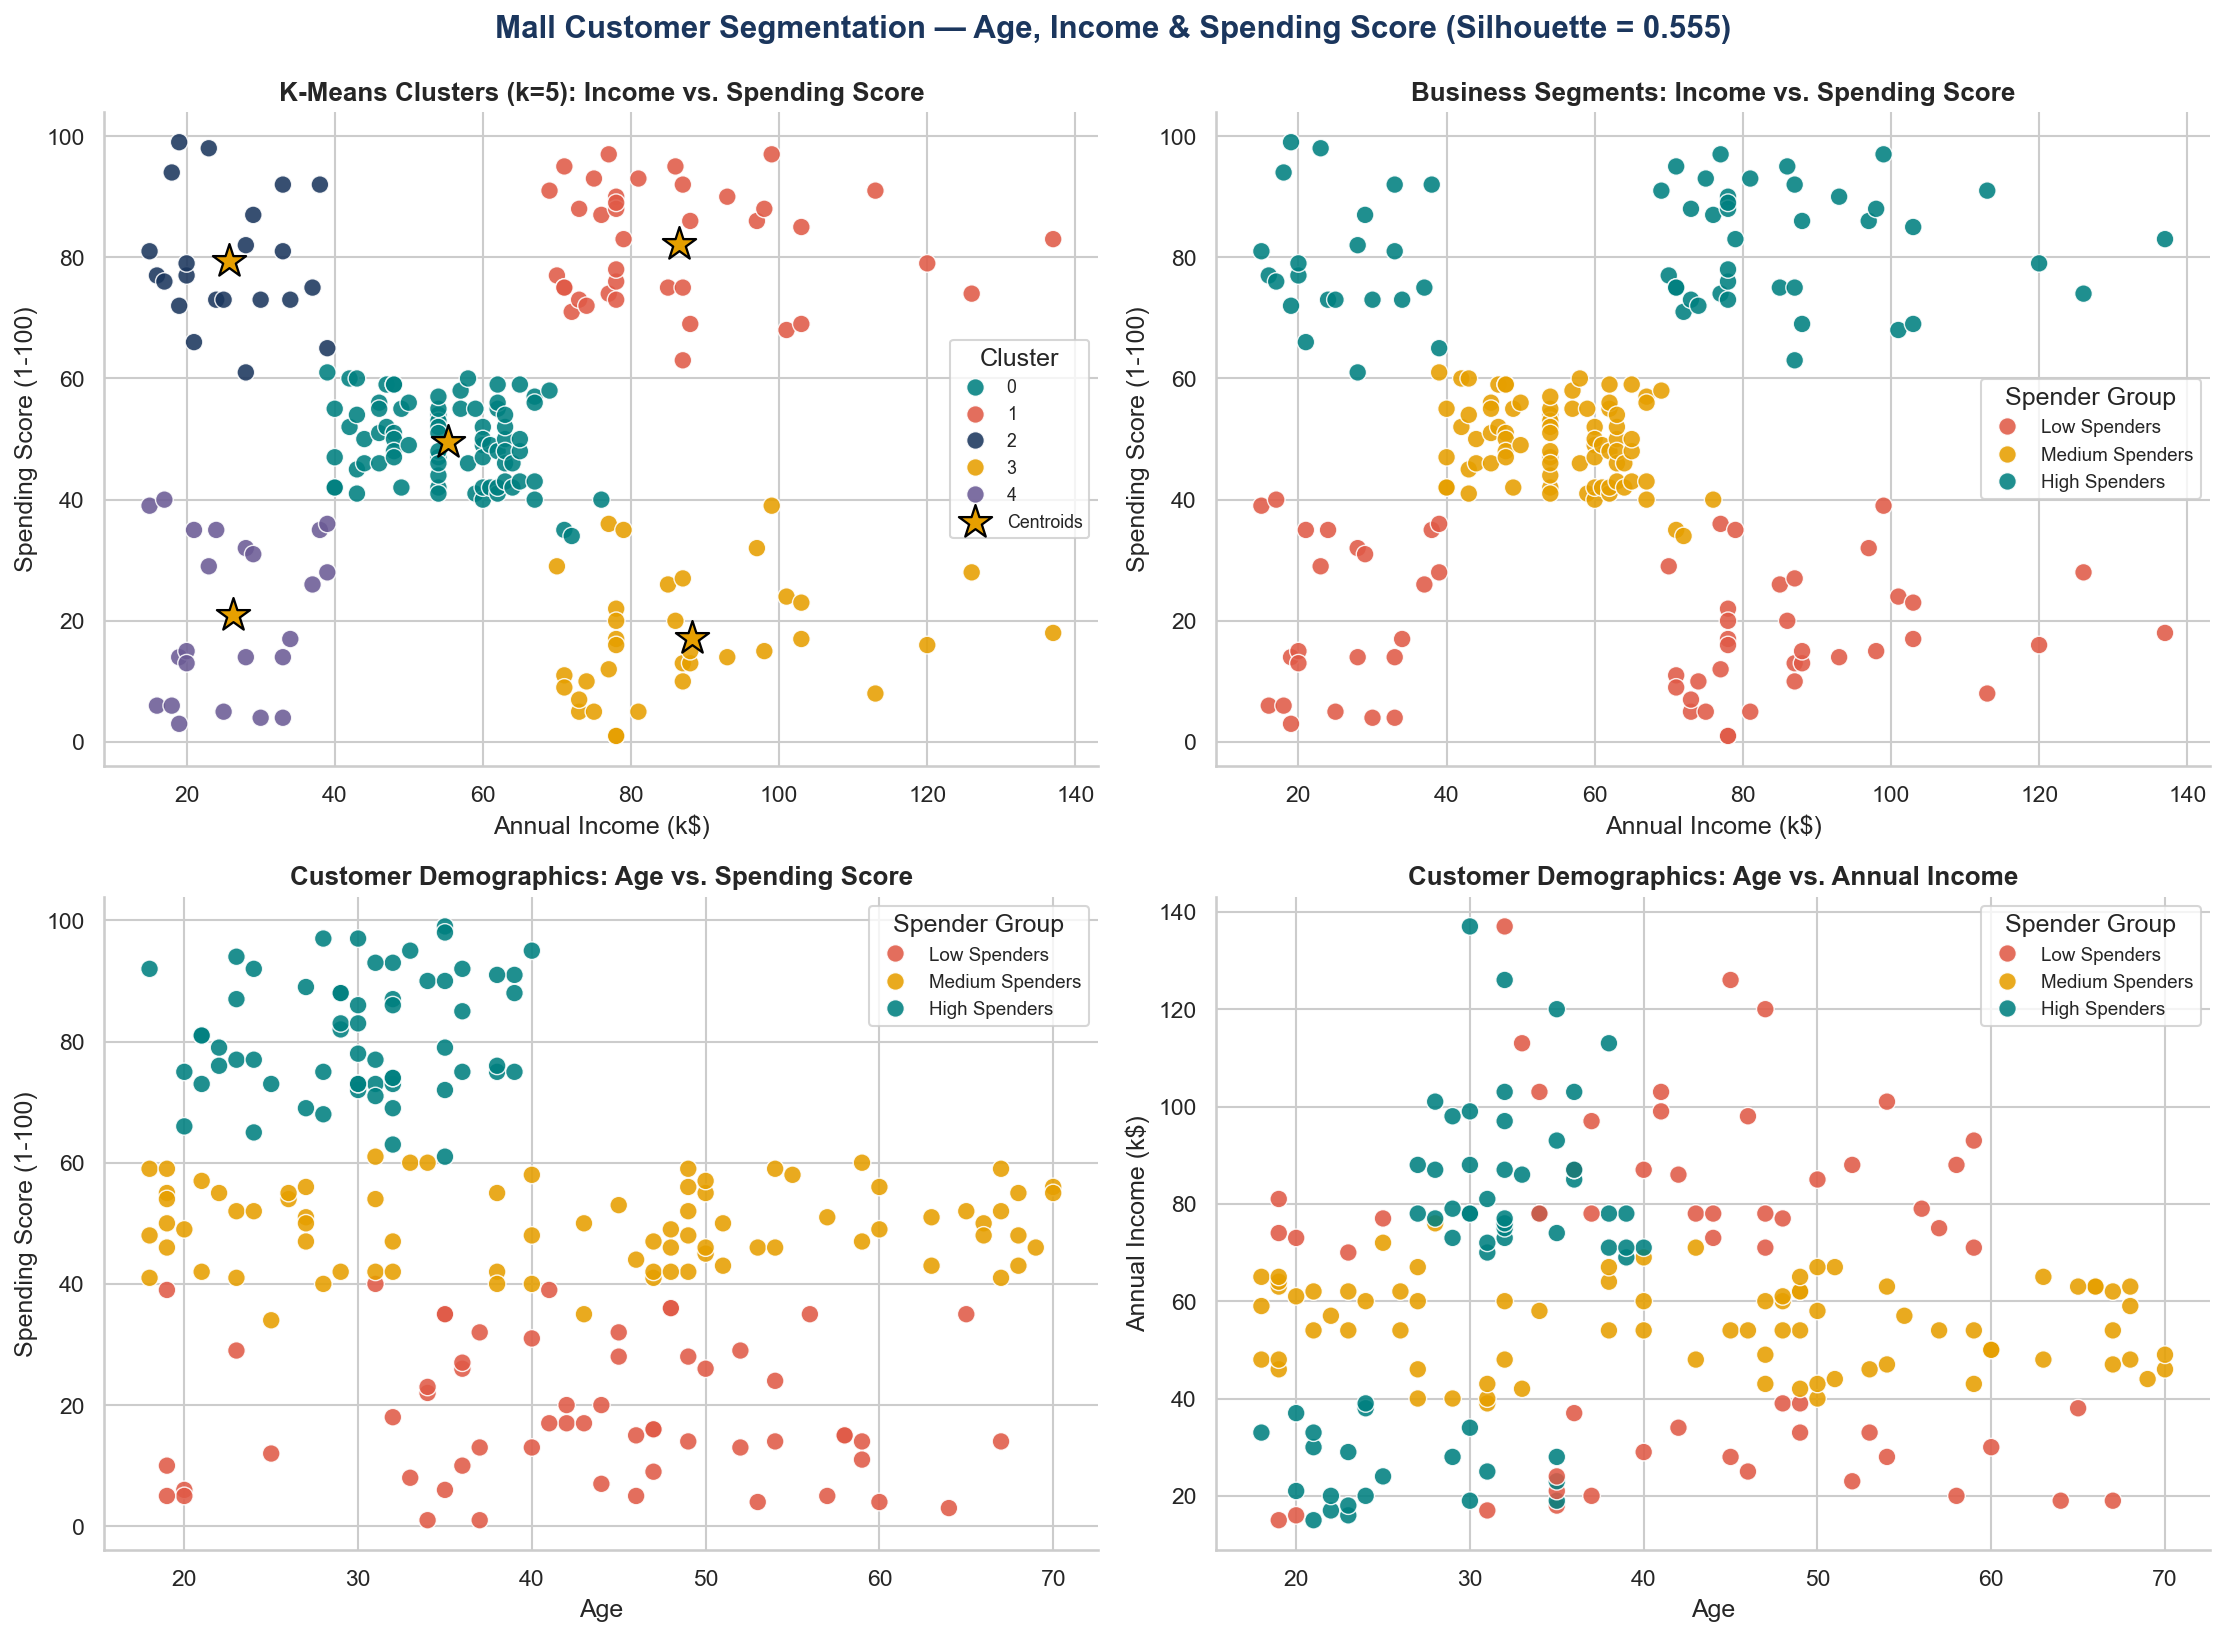

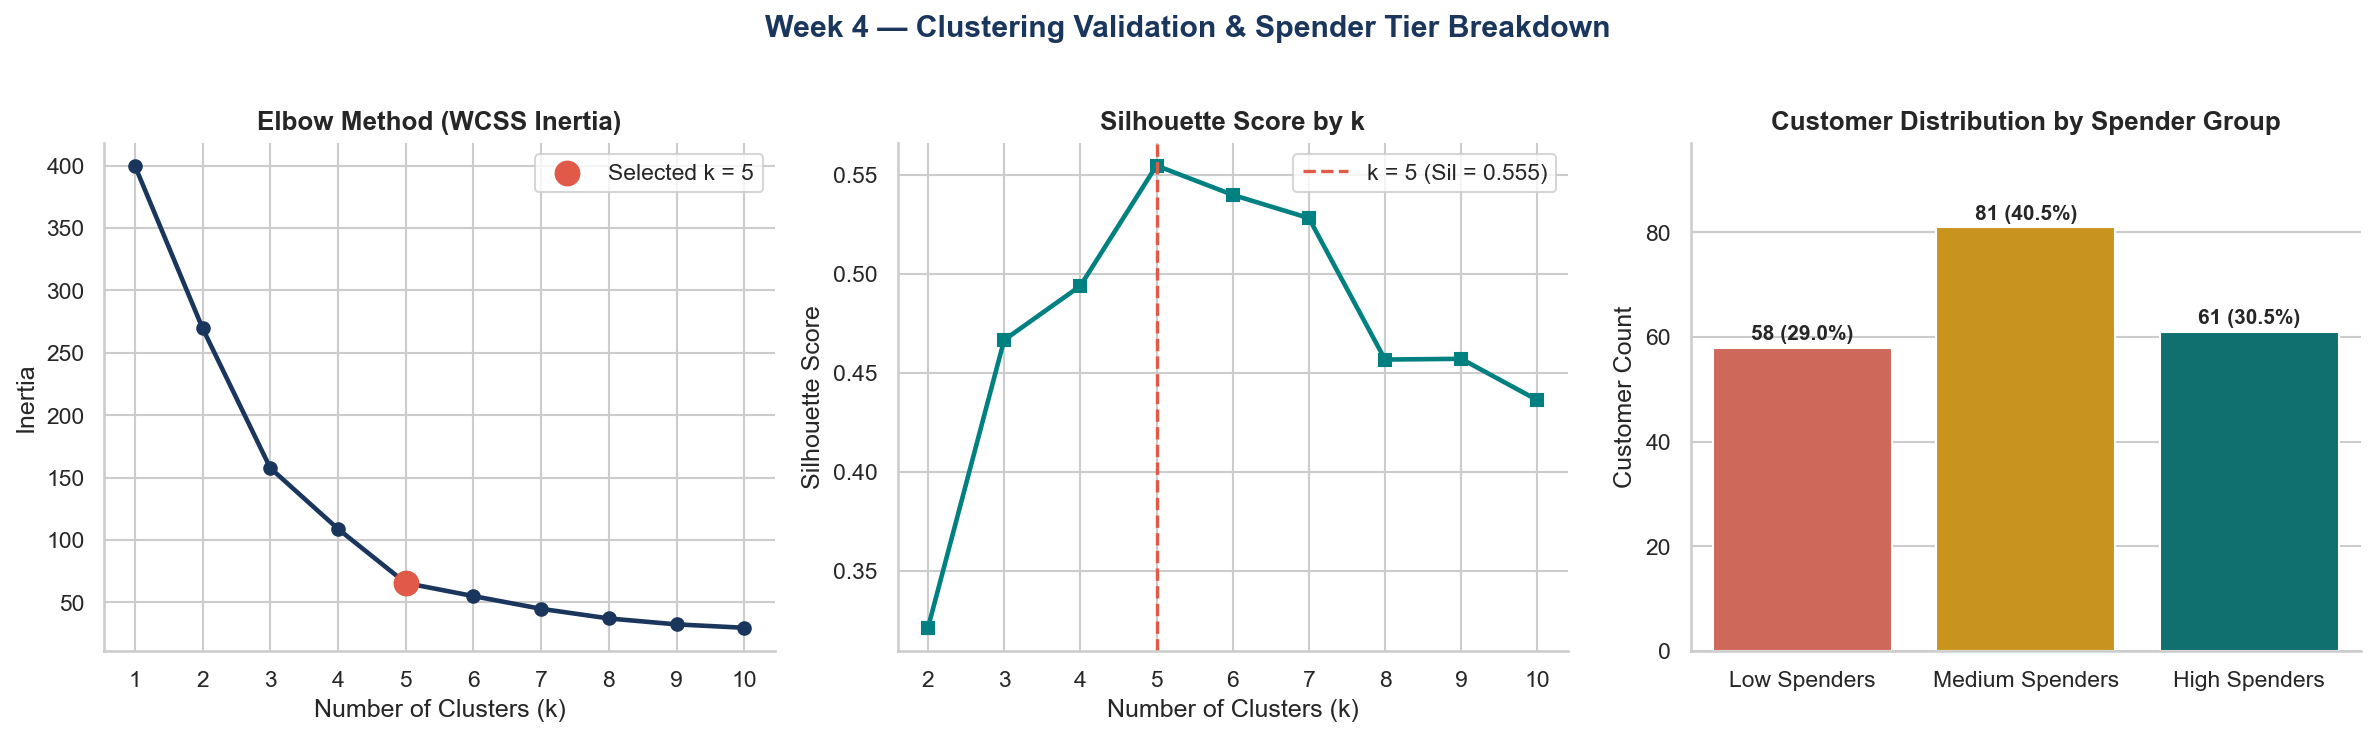

In [4]:
plot_customer_segments(res)
plot_segmentation_diagnostics(res)

display(Image(filename="outputs/customer_segments_overview.png"))
display(Image(filename="outputs/segmentation_diagnostics.png"))